# MNIST orthogonal class-dependent batch effect
## 1. Purpose / experiment definition
Two distinct, exactly class-balanced MNIST batches receive class-dependent perturbations in
orthogonal trailing-PC subspaces, with independent scale permutations in each batch.
Original pixels are the main experiment; signal-projected pixels provide the exact invariance control.
There is no observation pairing across batches.

Scientific construction and experiment loops are visible below. Existing library methods perform
OT, embeddings, scoring, strict artifact I/O, and manuscript drawing. Fixed ε and signal projection remain mechanism controls; extra rel_reg settings remain ablations.
MultiMAP is intentionally simplified to native defaults or k=15, as requested; the previous
controlled hyperparameters and preprocessing grid are no longer used for new runs.

Use the project Python environment (with the dependencies in `pyproject.toml`). Execute in order.
The full grid is expensive; the configuration cell gives an explicit smoke override.

## 2. Imports and global configuration
Change scientific parameters once here. Compute mode creates/resumes the deterministic named run;
load mode requires that exact compatible completed run. No latest-run discovery occurs.
MNIST downloading is opt-in. MultiMAP uses the repository's configured external environment.
The `SyntheticExperiment` object below stores state and supplies shared artifact/graph utilities;
its high-level experiment execution methods are deliberately not called.

In [22]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from ne_aligned_utils import paper
from ne_aligned_utils.experiments.synthetic import (
    CompetitorsConfig,
    CorruptionConfig,
    DataConfig,
    EmbeddingConfig,
    EvaluationConfig,
    ExperimentConfig,
    ExperimentPaths,
    OtConfig,
    SyntheticExperiment,
)
from ne_aligned_utils.paper.inputs import synthetic as saved_synthetic
from ne_aligned_utils.paper.figures.synthetic import build_variant

paper.use_paper_style()
import json
from functools import partial
from sklearn.decomposition import PCA
from torchvision.datasets import MNIST
from ne_aligned_utils.evaluation.metrics import compute_kbet, compute_neighbor_purity
from ne_aligned_utils.methods import (
    compute_ot_plan,
    compute_ot_tsne_embedding_from_plan,
    compute_scanorama_then_tsne_embedding_from_arrays,
)
from ne_aligned_utils.methods.external.multimap import compute_multimap_embedding_from_arrays
from ne_aligned_utils.experiments.synthetic import label_methods
from dataclasses import dataclass
from types import SimpleNamespace
from ne_aligned_utils.paper import layout, registry
from ne_aligned_utils.paper.figures import synthetic as drawing

In [23]:
# Execution paths; MNIST must exist unless download_mnist=True.
RUN_EXPERIMENT = False
RUN_NAME = None  # or an explicit completed run name
SAVE_PAPER_FIGURE = False
# Prefer this checkout's data; otherwise reuse the adjacent research checkout.
SOURCE_ROOT = ROOT
if not any((SOURCE_ROOT / rel / "MNIST/raw").is_dir() for rel in ("data/torchvision", "data")):
    SOURCE_ROOT = ROOT.parent / "ne-aligned"
print(f"MNIST source checkout: {SOURCE_ROOT}")

config = ExperimentConfig(
    data=DataConfig(
        random_seed=0,
        n_per_digit=100,
        signal_variance_target=0.90,
        signal_rank=None,
        tail_pool_size=30,
        tail_variance_rel_tol=1e-10,
        tail_pca_indices=None,
        modes=("original", "projected"),
    ),
    corruption=CorruptionConfig(
        magnitudes=(1.0, 4.0, 10.0, 20.0),
        corruption_seeds=(0, 1, 2),
        class_corruption_scales=tuple(np.linspace(0.35, 2.60, 10)),
        batch1_seed_offset=10_000,
        batch0_scale_seed_offset=20_000,
        batch1_scale_seed_offset=30_000,
    ),
    ot=OtConfig(
        epsilon_policies=("fixed_at_lambda_0", "adaptive_per_magnitude"),
        rel_reg=(1.0, 10.0),
        ot_effective_k=15,
        ot_tol=1e-12,
        ot_max_iter=10_000,
    ),
    competitors=CompetitorsConfig(
        cross_batch_k=15, run_multimap=True, run_scanorama_50_tsne=True, multimap_profile="default"
    ),
    # t-SNE schedule: 250 exaggerated + 500 iterations (openTSNE's defaults, as in the benchmark).
    # To reproduce or load runs saved before this change: n_epochs=200, early_exaggeration_iter=None.
    embedding=EmbeddingConfig(
        embedding_seeds=(0, 1, 2), n_epochs=500, early_exaggeration_iter=250
    ),
    evaluation=EvaluationConfig(kbet_k=15),
)
# Optional smoke grid: enable explicitly; these results are not manuscript estimates.
SMOKE = False
if SMOKE:
    from dataclasses import replace

    config = replace(
        config,
        data=replace(config.data, n_per_digit=10, signal_rank=10, tail_pool_size=5),
        corruption=replace(config.corruption, magnitudes=(10.0,), corruption_seeds=(0,)),
        ot=replace(config.ot, rel_reg=(1.0,)),
        competitors=replace(config.competitors),
        embedding=replace(config.embedding, embedding_seeds=(0,), n_epochs=10),
    )
mnist_root = SOURCE_ROOT / "data/torchvision"
if not (mnist_root / "MNIST/raw").is_dir() and (SOURCE_ROOT / "data/MNIST/raw").is_dir():
    mnist_root = SOURCE_ROOT / "data"
paths = ExperimentPaths(
    results_root=ROOT / "results", data_root=mnist_root, run_name=RUN_NAME, download_mnist=False
)
experiment = SyntheticExperiment(config, paths)
print("Experiment: MNIST orthogonal class-dependent batch effect")
print("Input representations: original pixels; signal-projected pixels")
print(f"Run: {experiment.run_dir.name}\nResults: {experiment.run_dir}")
print(f"Figure output (when enabled): {ROOT / 'results/paper_figures/synthetic_experiment/final'}")
if not RUN_EXPERIMENT:
    runs = experiment.load_saved()  # checks exact configuration; no MNIST/PCA/method execution
    print("Loaded compatible saved artifacts.")


# Diagnostic selection only; these values do not change the saved experiment grid.
@dataclass(frozen=True)
class DiagnosticConfig:
    magnitude: float = 10.0
    corruption_seed: int = 0
    rel_reg: float = 1.0
    mode: str = "original"


plot_config = DiagnosticConfig()  # choose λ here for the 10-digit clean/noisy grid

MNIST source checkout: /Users/azharakhmetova/ne-aligned
Experiment: MNIST orthogonal class-dependent batch effect
Input representations: original pixels; signal-projected pixels
Run: mnist_orthogonal_batch_effect__seed0__8274e751
Results: /Users/azharakhmetova/ne-aligned-submitted/results/mnist_orthogonal_batch_effect/mnist_orthogonal_batch_effect__seed0__8274e751
Figure output (when enabled): /Users/azharakhmetova/ne-aligned-submitted/results/paper_figures/synthetic_experiment/final
Loaded compatible saved artifacts.


## 3. Construct the clean MNIST batches
Sampling uses one seeded RNG in reference order. Split each digit's sampled indices, then shuffle
the batches independently. Loading reads the saved construction, without sampling or fitting PCA.

In [24]:
if RUN_EXPERIMENT:
    dataset = MNIST(paths.data_root, train=True, download=paths.download_mnist)
    all_x = dataset.data.numpy().reshape(-1, 28 * 28)
    all_y = dataset.targets.numpy().astype(int)
    rng = np.random.default_rng(config.data.random_seed)
    batch0_indices, batch1_indices = ([], [])
    for digit in range(10):
        candidates = np.flatnonzero(all_y == digit)
        selected = rng.choice(candidates, 2 * config.data.n_per_digit, replace=False)
        rng.shuffle(selected)
        batch0_indices.extend(selected[: config.data.n_per_digit])
        batch1_indices.extend(selected[config.data.n_per_digit :])
    batch0_indices = np.asarray(batch0_indices)
    batch1_indices = np.asarray(batch1_indices)
    rng.shuffle(batch0_indices)
    rng.shuffle(batch1_indices)
    if np.intersect1d(batch0_indices, batch1_indices).size:
        raise AssertionError("MNIST batches must be disjoint")
    x0_images = all_x[batch0_indices].astype(np.float64) / 255.0
    x1_images = all_x[batch1_indices].astype(np.float64) / 255.0
    labels0 = all_y[batch0_indices]
    labels1 = all_y[batch1_indices]
    expected = np.full(10, config.data.n_per_digit)
    if not (
        np.array_equal(np.bincount(labels0, minlength=10), expected)
        and np.array_equal(np.bincount(labels1, minlength=10), expected)
    ):
        raise AssertionError(
            "Each batch must contain exactly config.data.n_per_digit images per class"
        )
    for name in (
        "x0_images",
        "x1_images",
        "labels0",
        "labels1",
        "batch0_indices",
        "batch1_indices",
    ):
        setattr(experiment, name, locals()[name])
    experiment.labels = np.concatenate([labels0, labels1])
else:
    with np.load(experiment.run_dir / "data/construction.npz", allow_pickle=False) as data:
        labels0, labels1 = data["labels0"], data["labels1"]
        batch0_indices, batch1_indices = data["batch0_indices"], data["batch1_indices"]
assert not np.intersect1d(batch0_indices, batch1_indices).size
counts = pd.DataFrame(
    {"batch 0": np.bincount(labels0, minlength=10), "batch 1": np.bincount(labels1, minlength=10)}
)
assert counts.eq(config.data.n_per_digit).all().all()
print(f"Each batch: {len(labels0)} observations × 784 pixels; distinct source indices.")
display(counts.T)

Each batch: 1000 observations × 784 pixels; distinct source indices.


,0,1,2,3,4,5,6,7,8,9
batch 0,100,100,100,100,100,100,100,100,100,100
batch 1,100,100,100,100,100,100,100,100,100,100


## 4. Define the signal and nuisance subspaces
Full-SVD PCA fits pooled clean observations. Leading PCs retain the configured variance fraction.
The last numerically resolved 2m PCs are split into disjoint pools outside the signal PCs.
PC indices are zero-based; no choice depends on downstream performance.

In [25]:
if RUN_EXPERIMENT:
    experiment.x_images = np.vstack([experiment.x0_images, experiment.x1_images])
    experiment.pca = PCA(
        n_components=None, svd_solver="full", random_state=experiment.config.data.random_seed
    ).fit(experiment.x_images)
    experiment.n_components = experiment.pca.components_.shape[0]
    experiment.explained = experiment.pca.explained_variance_ratio_
    experiment.cumulative = np.cumsum(experiment.explained)
    experiment.signal_rank = (
        int(experiment.config.data.signal_rank)
        if experiment.config.data.signal_rank is not None
        else int(
            np.searchsorted(experiment.cumulative, experiment.config.data.signal_variance_target)
            + 1
        )
    )
    experiment.variance_resolution_threshold = (
        experiment.config.data.tail_variance_rel_tol * experiment.pca.explained_variance_[0]
    )
    experiment.resolved_indices = np.flatnonzero(
        experiment.pca.explained_variance_ > experiment.variance_resolution_threshold
    )
    if experiment.config.data.tail_pca_indices is None:
        if len(experiment.resolved_indices) < 2 * experiment.config.data.tail_pool_size:
            raise ValueError("Fewer than 2 * TAIL_POOL_SIZE numerically resolved PCs")
        experiment.joint_tail_indices = experiment.resolved_indices[
            -2 * experiment.config.data.tail_pool_size :
        ]
        experiment.alpha_tail_indices = experiment.joint_tail_indices[
            : experiment.config.data.tail_pool_size
        ]
        experiment.beta_tail_indices = experiment.joint_tail_indices[
            experiment.config.data.tail_pool_size :
        ]
        experiment.tail_indices = experiment.joint_tail_indices
    else:
        experiment.joint_tail_indices = np.asarray(
            experiment.config.data.tail_pca_indices, dtype=int
        )
        if len(experiment.joint_tail_indices) != 2 * experiment.config.data.tail_pool_size:
            raise ValueError("Explicit TAIL_PCA_INDICES must contain 2 * TAIL_POOL_SIZE entries")
        experiment.alpha_tail_indices = experiment.joint_tail_indices[
            : experiment.config.data.tail_pool_size
        ]
        experiment.beta_tail_indices = experiment.joint_tail_indices[
            experiment.config.data.tail_pool_size :
        ]
        experiment.tail_indices = experiment.joint_tail_indices
    if (
        experiment.signal_rank < 1
        or experiment.tail_indices.min() < experiment.signal_rank
        or experiment.tail_indices.max() >= experiment.n_components
    ):
        raise ValueError("Tail PCs must exist and lie strictly outside the leading signal subspace")
    assert len(np.unique(experiment.tail_indices)) == 2 * config.data.tail_pool_size
    assert not np.intersect1d(experiment.alpha_tail_indices, experiment.beta_tail_indices).size
    print(
        f"Signal rank: {experiment.signal_rank} PCs ({experiment.cumulative[experiment.signal_rank - 1]:.1%} variance)"
    )
    print("Batch 0 nuisance PCs:", experiment.alpha_tail_indices)
    print("Batch 1 nuisance PCs:", experiment.beta_tail_indices)
else:
    print("Saved signal rank:", runs.configs["original"]["signal_rank"])
    print(
        "Saved nuisance pools:",
        runs.configs["original"]["alpha_tail_pca_indices"],
        runs.configs["original"]["beta_tail_pca_indices"],
    )

Saved signal rank: 83
Saved nuisance pools: [554, 555, 556, 557, 558, 559, 560, 561, 562, 563, 564, 565, 566, 567, 568, 569, 570, 571, 572, 573, 574, 575, 576, 577, 578, 579, 580, 581, 582, 583] [584, 585, 586, 587, 588, 589, 590, 591, 592, 593, 594, 595, 596, 597, 598, 599, 600, 601, 602, 603, 604, 605, 606, 607, 608, 609, 610, 611, 612, 613]


### PCA spectrum and selected subspaces
The leading signal PCs are shaded; points highlight the two selected nuisance pools.
The second plot marks the selected rank against cumulative explained variance. Indices are zero-based.
Load-only mode reads the recorded PCA arrays; it does not refit PCA.

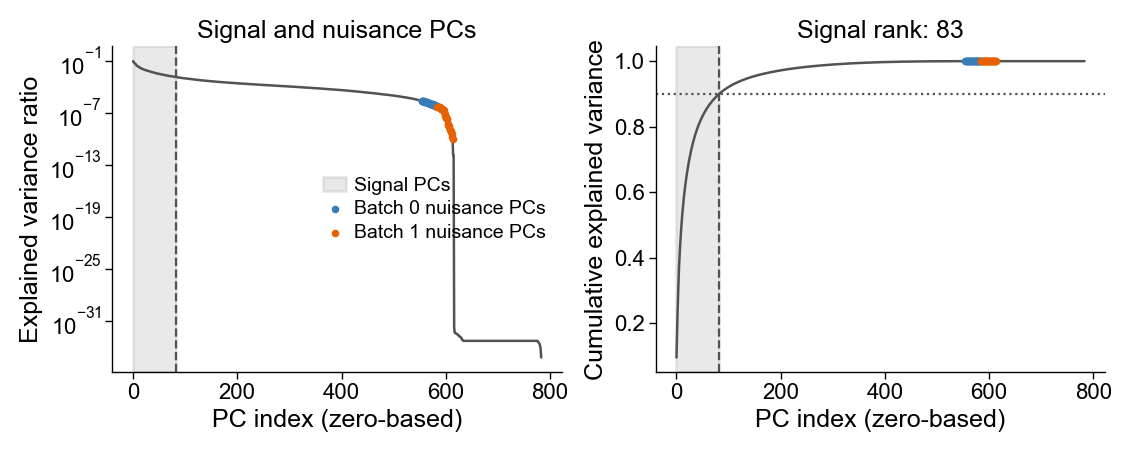

In [26]:
if RUN_EXPERIMENT:
    pca_components = experiment.pca.components_
    pca_mean = experiment.pca.mean_
    spectrum = experiment.pca.explained_variance_
    signal_rank = experiment.signal_rank
    nuisance0, nuisance1 = experiment.alpha_tail_indices, experiment.beta_tail_indices
else:
    with np.load(experiment.run_dir / "data/construction.npz", allow_pickle=False) as data:
        pca_components, pca_mean = data["pca_components"], data["pca_mean"]
        spectrum = data["pca_variance"]
    manifest = runs.configs["original"]
    signal_rank = int(manifest["signal_rank"])
    nuisance0 = np.asarray(manifest["alpha_tail_pca_indices"])
    nuisance1 = np.asarray(manifest["beta_tail_pca_indices"])
variance_ratio = spectrum / spectrum.sum()
cumulative = np.cumsum(variance_ratio)
pc_indices = np.arange(len(spectrum))
signal_color = registry.resolve("joint-pca").color
batch_colors = drawing.GALLERY_BATCH_COLOURS
fig, axes = plt.subplots(1, 2, figsize=layout.full_width(2.1), layout="constrained")
for ax, values in zip(axes, (variance_ratio, cumulative)):
    ax.plot(pc_indices, values, color=signal_color, linewidth=0.9)
    ax.axvspan(-0.5, signal_rank - 0.5, color=signal_color, alpha=0.12, label="Signal PCs")
    for batch, indices in enumerate((nuisance0, nuisance1)):
        ax.scatter(
            indices,
            values[indices],
            color=batch_colors[batch],
            s=12,
            label=f"Batch {batch} nuisance PCs",
            zorder=3,
        )
    ax.axvline(signal_rank - 1, color=signal_color, linestyle="--", linewidth=0.8)
    ax.set_xlabel("PC index (zero-based)")
axes[0].set(yscale="log", ylabel="Explained variance ratio", title="Signal and nuisance PCs")
axes[1].set(ylabel="Cumulative explained variance", title=f"Signal rank: {signal_rank}")
axes[1].axhline(
    config.data.signal_variance_target, color=signal_color, linestyle=":", linewidth=0.8
)
axes[0].legend(fontsize=drawing.PANEL_TITLE_PT)
plt.show()

## 5. Construct the class-dependent orthogonal batch effect
Draw Gaussian directions in each batch's nuisance basis, normalize, apply independently permuted
class scales, and center the ten vectors. Centering changes final norms; the audit retains both
assigned scales and resulting norms. Different seeded streams implement independence.
Orthogonality assertions protect the construction to numerical precision.

In [27]:
def make_class_corruptions(basis, seed, class_scales):
    rng = np.random.default_rng(seed)
    coefficients = rng.normal(size=(10, basis.shape[0]))
    directions = coefficients @ basis
    directions /= np.linalg.norm(directions, axis=1, keepdims=True)
    vectors = np.asarray(class_scales)[:, None] * directions
    return (vectors - vectors.mean(axis=0, keepdims=True), coefficients)

In [28]:
if RUN_EXPERIMENT:
    experiment.lead_basis = experiment.pca.components_[: experiment.signal_rank]
    experiment.alpha_tail_basis = experiment.pca.components_[experiment.alpha_tail_indices]
    experiment.beta_tail_basis = experiment.pca.components_[experiment.beta_tail_indices]
    experiment.alphas, experiment.betas = ({}, {})
    experiment.alpha_norms, experiment.beta_norms = ({}, {})
    audit_records = []
    for corruption_seed in experiment.config.corruption.corruption_seeds:
        scale_values = np.asarray(experiment.config.corruption.class_corruption_scales)
        alpha_scales = np.random.default_rng(
            corruption_seed + experiment.config.corruption.batch0_scale_seed_offset
        ).permutation(scale_values)
        beta_scales = np.random.default_rng(
            corruption_seed + experiment.config.corruption.batch1_scale_seed_offset
        ).permutation(scale_values)
        beta_seed = corruption_seed + experiment.config.corruption.batch1_seed_offset
        alpha, alpha_coefficients = make_class_corruptions(
            experiment.alpha_tail_basis, corruption_seed, alpha_scales
        )
        beta, beta_coefficients = make_class_corruptions(
            experiment.beta_tail_basis, beta_seed, beta_scales
        )
        alpha_norms = np.linalg.norm(alpha, axis=1)
        beta_norms = np.linalg.norm(beta, axis=1)
        assert np.linalg.norm(alpha.mean(axis=0)) < 1e-12
        assert np.linalg.norm(beta.mean(axis=0)) < 1e-12
        assert np.linalg.norm(alpha @ experiment.lead_basis.T, axis=1).max() < 1e-10
        assert np.linalg.norm(beta @ experiment.lead_basis.T, axis=1).max() < 1e-10
        assert np.max(np.abs(alpha @ beta.T)) < 1e-10
        experiment.alphas[corruption_seed], experiment.betas[corruption_seed] = (alpha, beta)
        experiment.alpha_norms[corruption_seed], experiment.beta_norms[corruption_seed] = (
            alpha_norms,
            beta_norms,
        )
        for batch, direction_seed, vectors, coefficients, norms, indices, scales in [
            (
                0,
                corruption_seed,
                alpha,
                alpha_coefficients,
                alpha_norms,
                experiment.alpha_tail_indices,
                alpha_scales,
            ),
            (
                1,
                beta_seed,
                beta,
                beta_coefficients,
                beta_norms,
                experiment.beta_tail_indices,
                beta_scales,
            ),
        ]:
            for digit in range(10):
                audit_records.append(
                    {
                        "corruption_seed": corruption_seed,
                        "batch": batch,
                        "direction_seed": direction_seed,
                        "class": digit,
                        "configured_scale": scales[digit],
                        "final_corruption_norm": norms[digit],
                        "leading_projection_norm": np.linalg.norm(
                            vectors[digit] @ experiment.lead_basis.T
                        ),
                        "tail_pca_indices": json.dumps(indices.tolist()),
                        "tail_pc_coefficients": json.dumps(coefficients[digit].tolist()),
                    }
                )
    experiment.audit = pd.DataFrame(audit_records)
    assert len(np.unique(experiment.tail_indices)) == len(experiment.tail_indices)
    assert not np.intersect1d(experiment.alpha_tail_indices, experiment.beta_tail_indices).size
    assert np.max(np.abs(experiment.alpha_tail_basis @ experiment.beta_tail_basis.T)) < 1e-10

In [29]:
if RUN_EXPERIMENT:
    # Persist config, clean arrays, PCA, and reference ε.
    experiment.initialize_run()
    audit = experiment.audit
else:
    audit = pd.read_csv(saved_synthetic.audit_path(runs.run_dirs["original"]))
for seed, draw in audit.groupby("corruption_seed"):
    scales = draw.pivot(index="class", columns="batch", values="configured_scale")
    np.testing.assert_array_equal(np.sort(scales[0]), np.sort(scales[1]))
assert audit.leading_projection_norm.max() < 1e-10
display(
    audit.groupby("batch")[["configured_scale", "final_corruption_norm", "leading_projection_norm"]]
    .agg(["min", "max"])
    .round(6)
)

configured_scale      final_corruption_norm            \
                   min  max                   min       max   
batch                                                         
0                 0.35  2.6              0.599485  2.437392   
1                 0.35  2.6              0.536259  2.414736   

      leading_projection_norm       
                          min  max  
batch                               
0                         0.0  0.0  
1                         0.0  0.0

### All digits: clean and corrupted batches
One example per digit, with the same observation shown clean and noisy within each batch.
Rows are batch 0 clean/noisy, then batch 1 clean/noisy; observations across batches are distinct.
Choose λ, representation, and corruption seed in `plot_config` above. Clipping to [0,1] is for
image display only; affinity and embedding calculations use the unclipped arrays.

Digit grid: original, λ=10, corruption seed 0


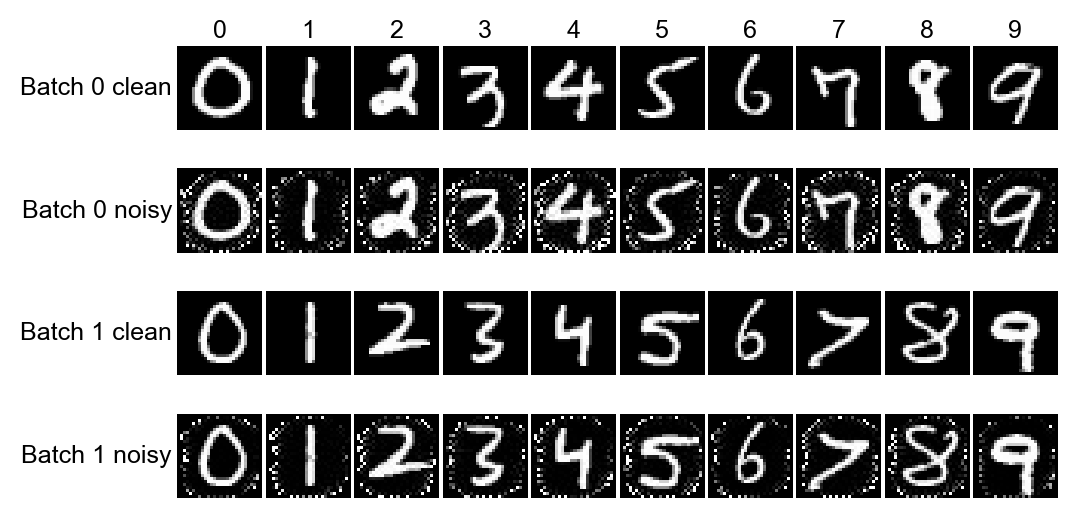

In [30]:
if RUN_EXPERIMENT:
    clean0, clean1 = experiment.x0_images, experiment.x1_images
else:
    with np.load(experiment.run_dir / "data/construction.npz", allow_pickle=False) as data:
        clean0, clean1 = data["clean0"], data["clean1"]
recorded_pca = SimpleNamespace(components_=pca_components)
alpha, beta = drawing.reconstruct_corruptions(
    "two_sided_independent_scales", audit, recorded_pca, plot_config.corruption_seed
)
if plot_config.mode == "original":
    display_clean = (clean0, clean1)
elif plot_config.mode == "projected":
    lead = pca_components[:signal_rank]
    display_clean = tuple((x - pca_mean) @ lead.T @ lead + pca_mean for x in (clean0, clean1))
else:
    raise ValueError("Diagnostic mode must be original or projected")
indices = [
    [np.flatnonzero(labels == digit)[0] for digit in range(10)] for labels in (labels0, labels1)
]
images = []
for batch, (clean, vectors) in enumerate(zip(display_clean, (alpha, beta))):
    examples = clean[indices[batch]]
    images.extend((examples, examples + plot_config.magnitude * vectors))
fig, axes = plt.subplots(4, 10, figsize=layout.full_width(2.8), layout="none")
row_labels = ("Batch 0 clean", "Batch 0 noisy", "Batch 1 clean", "Batch 1 noisy")
for row, (examples, label) in enumerate(zip(images, row_labels)):
    for digit, ax in enumerate(axes[row]):
        ax.imshow(np.clip(examples[digit], 0, 1).reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.set(xticks=[], yticks=[])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if row == 0:
            ax.set_title(str(digit))
    axes[row, 0].set_ylabel(label, rotation=0, ha="right", va="center")
fig.subplots_adjust(left=0.19, right=0.99, top=0.9, bottom=0.04, wspace=0.05, hspace=0.08)
print(
    f"Digit grid: {plot_config.mode}, λ={plot_config.magnitude:g}, "
    f"corruption seed {plot_config.corruption_seed}"
)
plt.show()

## 6. Sanity checks / visual validation
For corruption strength λ, the cost decomposes into clean cost, λ² row/column norm offsets,
and clean–nuisance interactions; the cross-nuisance term vanishes. Signal projection removes
the interactions. Adding only row/column offsets leaves a balanced OT plan invariant at fixed ε.
Adaptive ε can change the plan. Both policies are tested, including λ=0.

In [31]:
if RUN_EXPERIMENT:
    cost_records, experiment.reference_plans = ([], {})
    for mode in experiment.config.data.modes:
        base0, base1 = experiment.clean_by_mode[mode]
        clean_cost = experiment.squared_cost(base0, base1)
        for rel_reg in experiment.config.ot.rel_reg:
            for epsilon_policy in experiment.config.ot.epsilon_policies:
                experiment.reference_plans[mode, rel_reg, epsilon_policy] = (
                    experiment.compute_policy_plan(base0, base1, mode, rel_reg, epsilon_policy)
                )
        for corruption_seed in experiment.config.corruption.corruption_seeds:
            alpha, beta = (experiment.alphas[corruption_seed], experiment.betas[corruption_seed])
            alpha_i, beta_j = (alpha[experiment.labels0], beta[experiment.labels1])
            alpha_norms, beta_norms = (
                experiment.alpha_norms[corruption_seed],
                experiment.beta_norms[corruption_seed],
            )
            for magnitude in tuple(dict.fromkeys((0.0, *experiment.config.corruption.magnitudes))):
                x0, x1 = experiment.make_batches(mode, magnitude, corruption_seed)
                observed_cost = experiment.squared_cost(x0, x1)
                row_offset = magnitude**2 * alpha_norms[experiment.labels0] ** 2
                column_offset = magnitude**2 * beta_norms[experiment.labels1] ** 2
                residual = observed_cost - clean_cost - row_offset[:, None] - column_offset[None, :]
                if mode == "projected":
                    numerical_tolerance = 1e-09 * (
                        1.0 + np.max(clean_cost) + np.max(row_offset) + np.max(column_offset)
                    )
                    if np.max(np.abs(residual)) > numerical_tolerance:
                        raise AssertionError("Projected row-plus-column cost identity failed")
                alpha_signal = np.sum(base0 * alpha_i, axis=1)[:, None] - alpha_i @ base1.T
                beta_signal = base0 @ beta_j.T - np.sum(base1 * beta_j, axis=1)[None, :]
                signal_interaction = 2 * magnitude * (alpha_signal - beta_signal)
                nuisance_cross = -2 * magnitude**2 * (alpha_i @ beta_j.T)
                analytic_residual = signal_interaction + nuisance_cross
                identity_error = residual - analytic_residual
                offset_matrix = row_offset[:, None] + column_offset[None, :]
                offset_rms = float(np.sqrt(np.mean(offset_matrix**2)))
                for rel_reg in experiment.config.ot.rel_reg:
                    for epsilon_policy in experiment.config.ot.epsilon_policies:
                        plan, artifacts = experiment.compute_policy_plan(
                            x0, x1, mode, rel_reg, epsilon_policy, return_artifacts=True
                        )
                        reference = experiment.reference_plans[mode, rel_reg, epsilon_policy]
                        cost_records.append(
                            {
                                "mode": mode,
                                "corruption_seed": corruption_seed,
                                "magnitude": magnitude,
                                "rel_reg": rel_reg,
                                "epsilon_policy": epsilon_policy,
                                "epsilon": float(artifacts["epsilon"]),
                                "epsilon_over_reference": float(artifacts["epsilon"])
                                / experiment.reference_epsilons[mode][float(rel_reg)],
                                "row_offset_rms": float(np.sqrt(np.mean(row_offset**2))),
                                "column_offset_rms": float(np.sqrt(np.mean(column_offset**2))),
                                "row_plus_column_offset_rms": offset_rms,
                                "signal_interaction_rms": float(
                                    np.sqrt(np.mean(signal_interaction**2))
                                ),
                                "signal_interaction_max_abs": float(
                                    np.max(np.abs(signal_interaction))
                                ),
                                "alpha_beta_cross_rms": float(np.sqrt(np.mean(nuisance_cross**2))),
                                "row_plus_column_residual_rms": float(
                                    np.sqrt(np.mean(residual**2))
                                ),
                                "row_plus_column_residual_max_abs": float(np.max(np.abs(residual))),
                                "interaction_to_offset_rms_ratio": float(
                                    np.sqrt(np.mean(signal_interaction**2))
                                )
                                / offset_rms
                                if offset_rms
                                else 0.0,
                                "decomposition_identity_error_max_abs": float(
                                    np.max(np.abs(identity_error))
                                ),
                                "relative_ot_plan_change": float(
                                    np.linalg.norm(plan - reference) / np.linalg.norm(reference)
                                ),
                            }
                        )
    experiment.cost_diagnostics = pd.DataFrame(cost_records)
    experiment.verify_costs()
    experiment.save_stage("cost")
    cost = experiment.cost_diagnostics
else:
    cost = runs.cost

In [32]:
control = cost.query("mode == 'projected' and epsilon_policy == 'fixed_at_lambda_0'")
assert cost.decomposition_identity_error_max_abs.max() < 1e-8
assert len(control) and control.relative_ot_plan_change.max() < 1e-7
print("Maximum decomposition error:", cost.decomposition_identity_error_max_abs.max())
print("Projected fixed-ε relative plan change:", control.relative_ot_plan_change.max())
display(
    cost.groupby(["mode", "epsilon_policy"])[
        ["relative_ot_plan_change", "row_plus_column_residual_max_abs"]
    ]
    .max()
    .round(6)
)

Maximum decomposition error: 3.0358300273210357e-12
Projected fixed-ε relative plan change: 4.291119184363342e-15


relative_ot_plan_change  \
mode      epsilon_policy                                    
original  adaptive_per_magnitude                 0.186872   
          fixed_at_lambda_0                      0.005680   
projected adaptive_per_magnitude                 0.210652   
          fixed_at_lambda_0                      0.000000   

                                  row_plus_column_residual_max_abs  
mode      epsilon_policy                                            
original  adaptive_per_magnitude                         15.092137  
          fixed_at_lambda_0                              15.092137  
projected adaptive_per_magnitude                          0.000000  
          fixed_at_lambda_0                               0.000000

### Adaptive versus fixed ε
At the selected rel_reg, plot ε relative to its clean-data value and the relative OT-plan change.
Color identifies the representation; line style identifies the ε policy. The projected fixed-ε
curve should remain at numerical zero, whereas adapting ε can change the plan.

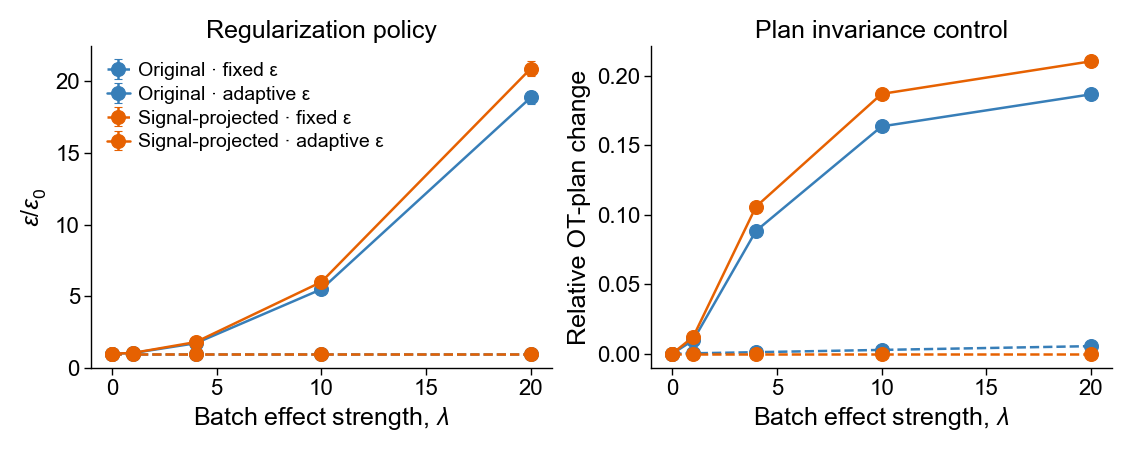

In [33]:
policy_diagnostics = cost.loc[np.isclose(cost.rel_reg, plot_config.rel_reg)]
if policy_diagnostics.empty:
    raise ValueError("Choose a diagnostic rel_reg present in the experiment grid")
fig, axes = plt.subplots(1, 2, figsize=layout.full_width(2.1), layout="constrained")
for mode, color in zip(("original", "projected"), batch_colors):
    for policy, linestyle, short in (
        ("fixed_at_lambda_0", "--", "fixed ε"),
        ("adaptive_per_magnitude", "-", "adaptive ε"),
    ):
        selected = policy_diagnostics.query("mode == @mode and epsilon_policy == @policy")
        label = f"{'Original' if mode == 'original' else 'Signal-projected'} · {short}"
        for ax, metric in zip(axes, ("epsilon_over_reference", "relative_ot_plan_change")):
            table = drawing.mean_sd(selected, metric)
            dashed = linestyle == "--"
            ax.errorbar(
                table.magnitude,
                table["mean"],
                yerr=table.sd.fillna(0),
                label=label,
                color=color,
                marker="o",
                markersize=3,
                markerfacecolor="white" if dashed else color,
                markeredgewidth=0.8,
                linewidth=1.1,
                linestyle=(0, (4, 2.5)) if dashed else "-",
                capsize=1.5,
            )
for ax in axes:
    ax.set_xlabel(r"Batch effect strength, $\lambda$")
axes[0].set(ylabel=r"$\epsilon / \epsilon_0$", title="Regularization policy")
axes[1].set(ylabel="Relative OT-plan change", title="Plan invariance control")
axes[0].legend(fontsize=drawing.PANEL_TITLE_PT, handlelength=4.0)
plt.show()

### Paper panel A: existing strip layout
This calls the same strip construction function as the final paper figure (four representative
digits at λ=10). The previous notebook preview selected the alternate column layout;
the images themselves were not transposed. The paper drawing code is unchanged.

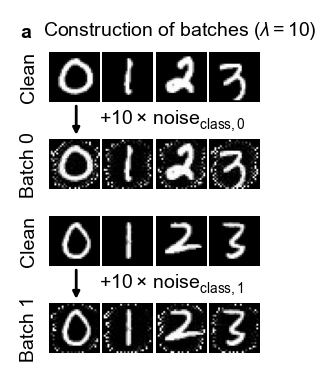

In [34]:
paper_seed = int(config.corruption.corruption_seeds[0])
paper_alpha, paper_beta = drawing.reconstruct_corruptions(
    "two_sided_independent_scales", audit, recorded_pca, paper_seed
)
with plt.rc_context({"figure.constrained_layout.use": False}):
    fig = plt.figure(figsize=layout.full_width(2.0))
    grid = fig.add_gridspec(1, 1)
    drawing.construction_panel_strip(
        fig,
        grid[0],
        clean0,
        labels0,
        clean1,
        labels1,
        paper_alpha,
        paper_beta,
        variant="two_sided_independent_scales",
        centred=True,
        inline=True,
    )
    drawing.lay_out_panels(fig)
    plt.show()

## 7. Cross-batch affinity experiment: EOT, shared kNN, mutual kNN
Extract top-k row and column supports from rectangular EOT plans. Shared supports are unions;
mutual supports are intersections. The existing graph utilities evaluate edge purity and the
fraction of query observations with a nonempty support. Coverage matters: high mutual purity
can coexist with isolated observations. The same diagnostics are measured for cross-batch kNN.

The fraction table averages corruption seeds separately for each representation and λ.
`within_batch_knn_edge_preservation` measures the fraction of each observation’s clean
within-batch kNN neighbors retained after corruption, averaged over observations and then
equally across batches. It excludes the observation itself. A value of 1 means all k neighbors
are retained; 0 means none. This measures neighborhood stability, not digit purity or batch mixing.

In [35]:
if RUN_EXPERIMENT:
    DIAGNOSTIC_MAGNITUDES = tuple(dict.fromkeys((0.0, *experiment.config.corruption.magnitudes)))
    affinity_records, knn_records = ([], [])
    for mode in experiment.config.data.modes:
        base0, base1 = experiment.clean_by_mode[mode]
        same_digit = experiment.labels0[:, None] == experiment.labels1[None, :]
        for corruption_seed in experiment.config.corruption.corruption_seeds:
            for magnitude in DIAGNOSTIC_MAGNITUDES:
                x0, x1 = experiment.make_batches(mode, magnitude, corruption_seed)
                for rel_reg in experiment.config.ot.rel_reg:
                    for epsilon_policy in experiment.config.ot.epsilon_policies:
                        plan, artifacts = experiment.compute_policy_plan(
                            x0, x1, mode, rel_reg, epsilon_policy, return_artifacts=True
                        )
                        reference = experiment.reference_plans[mode, rel_reg, epsilon_policy]
                        row_support = experiment.rectangular_topk_support(
                            plan, experiment.config.competitors.cross_batch_k, axis=1
                        )
                        column_support = experiment.rectangular_topk_support(
                            plan, experiment.config.competitors.cross_batch_k, axis=0
                        )
                        shared_support = row_support | column_support
                        mutual_support = row_support & column_support
                        row_purity, row_coverage, row_degree = experiment.support_stats(
                            row_support, experiment.labels0, experiment.labels1
                        )
                        column_purity, column_coverage, column_degree = experiment.support_stats(
                            column_support.T, experiment.labels1, experiment.labels0
                        )
                        shared_purity, shared_coverage, shared_degree = experiment.support_stats(
                            shared_support, experiment.labels0, experiment.labels1
                        )
                        mutual_purity, mutual_coverage, mutual_degree = experiment.support_stats(
                            mutual_support, experiment.labels0, experiment.labels1
                        )
                        affinity_records.append(
                            {
                                "mode": mode,
                                "corruption_seed": corruption_seed,
                                "magnitude": magnitude,
                                "rel_reg": rel_reg,
                                "epsilon_policy": epsilon_policy,
                                "epsilon": float(artifacts["epsilon"]),
                                "raw_same_digit_mass_fraction": float(
                                    plan[same_digit].sum() / plan.sum()
                                ),
                                "relative_ot_plan_change": float(
                                    np.linalg.norm(plan - reference) / np.linalg.norm(reference)
                                ),
                                "top_k": experiment.config.competitors.cross_batch_k,
                                "eot_row_digit_purity": row_purity,
                                "eot_row_nonempty_row_fraction": row_coverage,
                                "eot_row_mean_degree": row_degree,
                                "eot_column_digit_purity": column_purity,
                                "eot_column_nonempty_row_fraction": column_coverage,
                                "eot_column_mean_degree": column_degree,
                                "eot_shared_or_digit_purity": shared_purity,
                                "eot_shared_or_nonempty_row_fraction": shared_coverage,
                                "eot_shared_or_mean_degree": shared_degree,
                                "eot_mutual_and_digit_purity": mutual_purity,
                                "eot_mutual_and_nonempty_row_fraction": mutual_coverage,
                                "eot_mutual_and_mean_degree": mutual_degree,
                            }
                        )
                diagnostics = experiment.knn_diagnostics(
                    base0, base1, x0, x1, experiment.config.competitors.cross_batch_k
                )
                knn_records.append(
                    {
                        "mode": mode,
                        "corruption_seed": corruption_seed,
                        "magnitude": magnitude,
                        "k": experiment.config.competitors.cross_batch_k,
                        **diagnostics,
                    }
                )
    experiment.affinity_diagnostics = pd.DataFrame(affinity_records)
    experiment.knn_diagnostics_table = pd.DataFrame(knn_records)
    experiment.save_stage("affinity")
    affinity, knn = experiment.affinity_diagnostics, experiment.knn_diagnostics_table
else:
    affinity, knn = runs.affinity, runs.knn

In [36]:
display(
    affinity.query("epsilon_policy == 'adaptive_per_magnitude' and rel_reg == 1")
    .groupby(["mode", "magnitude"])[
        [
            "eot_row_digit_purity",
            "eot_shared_or_digit_purity",
            "eot_mutual_and_digit_purity",
            "eot_mutual_and_nonempty_row_fraction",
        ]
    ]
    .mean()
    .round(3)
)

eot_row_digit_purity  eot_shared_or_digit_purity  \
mode      magnitude                                                     
original  0.0                       0.737                       0.686   
          1.0                       0.737                       0.685   
          4.0                       0.735                       0.684   
          10.0                      0.733                       0.681   
          20.0                      0.732                       0.681   
projected 0.0                       0.739                       0.688   
          1.0                       0.738                       0.687   
          4.0                       0.735                       0.684   
          10.0                      0.734                       0.683   
          20.0                      0.734                       0.682   

                     eot_mutual_and_digit_purity  \
mode      magnitude                                
original  0.0                              0.805   
          1.0                              0.806   
          4.0                              0.808   
          10.0                             0.810   
          20.0                             0.810   
projected 0.0                              0.810   
          1.0                              0.811   
          4.0                              0.811   
          10.0                             0.814   
          20.0                             0.815   

                     eot_mutual_and_nonempty_row_fraction  
mode      magnitude                                        
original  0.0                                       0.990  
          1.0                                       0.990  
          4.0                                       0.988  
          10.0                                      0.987  
          20.0                                      0.988  
projected 0.0                                       0.991  
          1.0                                       0.991  
          4.0                                       0.990  
          10.0                                      0.989  
          20.0                                      0.988

shared_correct_class_neighbor_fraction  \
mode      magnitude                                           
original  0.0                                         0.667   
          1.0                                         0.661   
          4.0                                         0.422   
          10.0                                        0.195   
          20.0                                        0.113   
projected 0.0                                         0.679   
          1.0                                         0.674   
          4.0                                         0.425   
          10.0                                        0.196   
          20.0                                        0.113   

                     mutual_correct_class_neighbor_fraction  \
mode      magnitude                                           
original  0.0                                         0.813   
          1.0                                         0.815   
          4.0                                         0.702   
          10.0                                        0.500   
          20.0                                        0.343   
projected 0.0                                         0.809   
          1.0                                         0.811   
          4.0                                         0.688   
          10.0                                        0.494   
          20.0                                        0.344   

                     mutual_nonempty_row_fraction  \
mode      magnitude                                 
original  0.0                               0.984   
          1.0                               0.983   
          4.0                               0.566   
          10.0                              0.160   
          20.0                              0.107   
projected 0.0                               0.990   
          1.0                               0.989   
          4.0                               0.569   
          10.0                              0.166   
          20.0                              0.109   

                     within_batch_knn_edge_preservation  
mode      magnitude                                      
original  0.0                                     1.000  
          1.0                                     0.903  
          4.0                                     0.720  
          10.0                                    0.707  
          20.0                                    0.707  
projected 0.0                                     1.000  
          1.0                                     0.903  
          4.0                                     0.728  
          10.0                                    0.716  
          20.0                                    0.716

### kNN fractions and within-batch neighborhood preservation
Mean across corruption seeds, grouped by representation and λ. The last column reports the fraction of clean within-batch neighbors retained after corruption.

In [ ]:
display(
    knn.groupby(["mode", "magnitude"])[
        [
            "shared_correct_class_neighbor_fraction",
            "mutual_correct_class_neighbor_fraction",
            "mutual_nonempty_row_fraction",
            "within_batch_knn_edge_preservation",
        ]
    ]
    .mean()
    .round(3)
)

### Paper panel B: sparse OT versus shared and mutual kNN
Reuse the manuscript's symmetrized-affinity panel immediately after the affinity experiment.
The companion coverage diagnostic shows how many observations retain a mutual match.
These plots use the already computed/saved tables; no embedding results are needed.

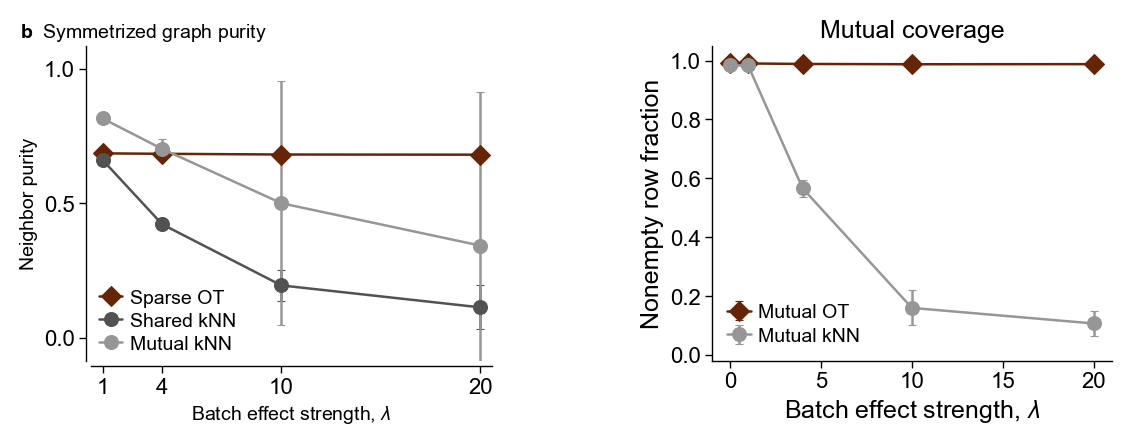

In [37]:
affinity_view = SimpleNamespace(
    configs={"original": {"magnitudes": config.corruption.magnitudes}}, knn=knn
)
directed = affinity.loc[
    (affinity["mode"] == "original")
    & (affinity.epsilon_policy == "adaptive_per_magnitude")
    & np.isclose(affinity.rel_reg, plot_config.rel_reg)
]
with plt.rc_context({"figure.constrained_layout.use": False}):
    fig = plt.figure(figsize=layout.full_width(2.2))
    grid = fig.add_gridspec(1, 2, wspace=0.55)
    drawing.mechanism_panels(
        fig,
        (grid[0],),
        "two_sided_independent_scales",
        affinity_view,
        directed,
        letters=("B",),
        directed_panel=False,
    )
    ax = fig.add_subplot(grid[1])
    original_knn = knn.query("mode == 'original'")
    for frame, field, label, color, marker in (
        (
            directed,
            "eot_mutual_and_nonempty_row_fraction",
            "Mutual OT",
            registry.resolve("ot").color,
            registry.resolve("ot").marker,
        ),
        (
            original_knn,
            "mutual_nonempty_row_fraction",
            "Mutual kNN",
            registry.resolve("joint").color,
            "o",
        ),
    ):
        drawing.add_curve(ax, frame, field, label=label, color=color, marker=marker)
    ax.set(
        xlabel=r"Batch effect strength, $\lambda$",
        ylabel="Nonempty row fraction",
        title="Mutual coverage",
        ylim=(-0.02, 1.05),
    )
    ax.legend(fontsize=drawing.PANEL_TITLE_PT)
    drawing.lay_out_panels(fig)
    plt.show()

### Receiving-side hubness and coverage (cross-batch k=15)
For each receiving point j, count distinct opposite-batch senders: Nₖ(j). Histograms at λ=10
normalize each graph/batch/seed by its own mean, including zero-degree points. The y-axis
is logarithmic to show sparse tails; the x-axis stays linear so anti-hubs at zero remain visible. Tables report
anti-hub fraction, maximum occurrence, and population skewness (undefined for constant counts).
The λ=10 summary averages anti-hub fractions/skewness over seeds and takes the largest
per-seed maximum. Raw per-seed values are saved. Coverage is the fraction with Nₖ≥1,
with mean ± sample SD over the existing corruption seeds.
Directed 0→1 has receiving batch 1 only; directed 1→0 has receiving batch 0 only.

We use the same input representation and Euclidean neighbors as the purity analysis. Mutual/shared
kNN are the intersection/union of both directed selections. Sparsified OT is the **cross-batch
row-top-15/column-top-15 union used in the affinity purity comparison**, at the diagnostic rel_reg
and adaptive ε. This is not the embedding's four-block effective-k graph. Symmetrized shared kNN
and this OT support guarantee positive degree on both sides: their coverage is structurally one,
although their in-degree distributions can be uneven. Heavy tails or concentration near 1 are
hypotheses to inspect, not imposed results. Independent normalization avoids conflating unequal
batch sizes with hubness; no within-batch edges or affinity weights enter the counts.

`COMPUTE_HUBNESS=True` computes only these graph diagnostics, including from a saved construction;
it does not run embeddings or change seeds/λ values. Otherwise read a compatible saved diagnostic.
MultiMAP connectivities and Scanorama MNN pairs were not retained in the existing artifact
interfaces, so those optional receiving-graph diagnostics are skipped (coordinates are not graphs).

In [ ]:
from ne_aligned_utils.evaluation.hubness import (
    cross_batch_occurrences, occurrence_statistics, summarize_coverage, restore_saved_construction,
)
from ne_aligned_utils.paper.figures.hubness import occurrence_histograms, receiving_coverage_figure
from ne_aligned_utils.methods import compute_ot_plan

COMPUTE_HUBNESS = RUN_EXPERIMENT  # Set True to add diagnostics to an already completed run.
HUBNESS_K, HUBNESS_MAGNITUDE = 15, 10.0
hubness_dir = experiment.run_dir / "diagnostics/hubness"
hubness_settings = dict(schema="cross_batch_topk_union_v1", k=HUBNESS_K,
    rel_reg=plot_config.rel_reg, epsilon_policy="adaptive_per_magnitude",
    histogram_magnitude=HUBNESS_MAGNITUDE,
    construction_sha256=json.loads((experiment.run_dir / "config.json").read_text())["construction_sha256"])
hubness_stats = hubness_points = None

In [ ]:
if COMPUTE_HUBNESS:
    if not RUN_EXPERIMENT:
        restore_saved_construction(experiment)  # Saved indices/PCA/directions; no sampling or fitting.
    hubness_records, histogram_records = [], []
    for mode in config.data.modes:
        for corruption_seed in config.corruption.corruption_seeds:
            for magnitude in tuple(dict.fromkeys((0.0, *config.corruption.magnitudes))):
                x0, x1 = experiment.make_batches(mode, magnitude, corruption_seed)
                plan = compute_ot_plan(x0, x1, rel_reg=plot_config.rel_reg,
                    tol=config.ot.ot_tol, max_iter=config.ot.ot_max_iter)
                points = cross_batch_occurrences(
                    experiment.directed_knn(x0, x1, HUBNESS_K),
                    experiment.directed_knn(x1, x0, HUBNESS_K),
                    experiment.rectangular_topk_support(plan, HUBNESS_K, axis=1),
                    experiment.rectangular_topk_support(plan, HUBNESS_K, axis=0))
                metadata = dict(mode=mode, magnitude=magnitude, corruption_seed=corruption_seed,
                                k=HUBNESS_K, rel_reg=plot_config.rel_reg,
                                epsilon_policy="adaptive_per_magnitude")
                hubness_records.append(occurrence_statistics(points).assign(**metadata))
                if magnitude == HUBNESS_MAGNITUDE:
                    histogram_records.append(points.assign(**metadata))
            print(f"Receiving-graph diagnostics: {mode}, corruption seed {corruption_seed}")
    hubness_stats = pd.concat(hubness_records, ignore_index=True)
    hubness_points = (pd.concat(histogram_records, ignore_index=True) if histogram_records
                      else pd.DataFrame(columns=[*points.columns, *metadata]))
    hubness_dir.mkdir(parents=True, exist_ok=True)
    hubness_stats.to_csv(hubness_dir / "receiving_coverage_metrics_raw.csv", index=False)
    hubness_points.to_csv(hubness_dir / "k_occurrence_lambda10.csv", index=False)
    summarize_coverage(hubness_stats).to_csv(
        hubness_dir / "receiving_coverage_metrics_summary.csv", index=False)
    (hubness_dir / "config.json").write_text(json.dumps(hubness_settings, indent=2, sort_keys=True))
elif (hubness_dir / "config.json").is_file():
    if json.loads((hubness_dir / "config.json").read_text()) != hubness_settings:
        raise ValueError("Saved hubness diagnostic settings differ; explicitly recompute diagnostics.")
    hubness_stats = pd.read_csv(hubness_dir / "receiving_coverage_metrics_raw.csv")
    hubness_points = pd.read_csv(hubness_dir / "k_occurrence_lambda10.csv")
else:
    print("No saved receiving-graph diagnostics. Set COMPUTE_HUBNESS=True above and rerun "
          "this subsection; the existing embeddings and purity results are reused.")

In [ ]:
if hubness_stats is not None:
    if not hubness_points.empty:
        for mode in config.data.modes:
            occurrence_histograms(hubness_points.loc[hubness_points["mode"] == mode],
                                  title=f"{mode} · λ=10 · cross-batch k=15")
            plt.show()
        display(hubness_stats.loc[hubness_stats.magnitude == HUBNESS_MAGNITUDE]
            .groupby(["mode", "graph", "receiving_batch"])
            .agg(anti_hub_fraction=("anti_hub_fraction", "mean"),
                 max_k_occurrence=("max_k_occurrence", "max"), skewness=("skewness", "mean"))
            .round(3))
    else:
        print("λ=10 is absent from this run's grid; no histogram cases were added.")
    receiving_coverage_figure(summarize_coverage(hubness_stats), config.data.modes)
    plt.show()
    print(f"Full per-seed statistics, λ=10 counts, summary and settings: {hubness_dir}")

## 8. Embedding experiment
Each method definition below creates its own explicit method metadata and invokes the repository
method API through the strict cache utility. Compatible coordinates resume; incompatible sidecars
raise an error. Purity uses the current macro-by-label metric with a 15-neighbor cap; kBET uses
the configured neighborhood and digit conditioning. Full per-seed tables are saved.
The final short loop applies these definitions across the configured grid.

In [38]:
def score_embedding(meta, embedding, runtime, path, display_method):
    batch_ids = np.r_[np.zeros(len(experiment.labels0), int), np.ones(len(experiment.labels1), int)]
    return {
        **meta,
        "display_method": display_method,
        "purity": compute_neighbor_purity(embedding, experiment.labels),
        "kbet": compute_kbet(embedding, batch_ids, experiment.labels, k=config.evaluation.kbet_k),
        "runtime_seconds": runtime,
        "cache_path": str(path),
    }

### OT-tSNE
Use the balanced rectangular plan, configured effective k, random initialization, and each ε/rel_reg
combination. Plan reuse across embedding seeds avoids solving the same transport problem again.

In [39]:
def ot_embeddings(x0, x1, mode, magnitude, corruption_seed, embedding_seed):
    records = []
    for rel_reg in experiment.config.ot.rel_reg:
        for epsilon_policy in experiment.config.ot.epsilon_policies:
            plan_key = (mode, corruption_seed, magnitude, rel_reg, epsilon_policy)
            if plan_key not in embedding_plan_cache:
                embedding_plan_cache[plan_key] = experiment.compute_policy_plan(
                    x0, x1, mode, rel_reg, epsilon_policy, return_artifacts=True
                )
            plan, artifacts = embedding_plan_cache[plan_key]
            display_method = f"OT-tSNE ({epsilon_policy}, rel_reg={rel_reg:g})"
            path = experiment.cache_path(
                mode,
                magnitude,
                "ot",
                "tsne",
                corruption_seed,
                embedding_seed,
                epsilon_policy,
                rel_reg,
                experiment.config.ot.ot_effective_k,
            )
            meta = dict(
                mode=mode,
                magnitude=magnitude,
                method="ot",
                backend="tsne",
                corruption_seed=corruption_seed,
                embedding_seed=embedding_seed,
                rel_reg=rel_reg,
                epsilon=float(artifacts["epsilon"]),
                epsilon_policy=epsilon_policy,
                effective_k=experiment.config.ot.ot_effective_k,
            )
            embedding, runtime = experiment.load_or_compute(
                path,
                lambda plan=plan, embedding_seed=embedding_seed, x0=x0, x1=x1: (
                    compute_ot_tsne_embedding_from_plan(
                        plan,
                        effective_k=experiment.config.ot.ot_effective_k,
                        random_state=embedding_seed,
                        n_epochs=experiment.config.embedding.n_epochs,
                        early_exaggeration_iter=experiment.config.embedding.early_exaggeration_iter,
                        init="random",
                        backend="tsne",
                        x_joint=np.vstack([x0, x1]),
                    )
                ),
                meta,
            )
            records.append(score_embedding(meta, embedding, runtime, path, display_method))
    return records

### Scanorama + t-SNE
Integrate in 50 dimensions with exact matching (`approx=False`), then run t-SNE with perplexity 30
and the configured embedding seed and iteration count.

In [40]:
def scanorama_embeddings(x0, x1, mode, magnitude, corruption_seed, embedding_seed):
    records = []
    if experiment.config.competitors.run_scanorama_50_tsne:
        display_method, key = ("Scanorama + t-SNE (50d)", "scanorama-50-tsne")
        path = experiment.cache_path(mode, magnitude, key, "tsne", corruption_seed, embedding_seed)
        meta = dict(
            mode=mode,
            magnitude=magnitude,
            method=key,
            backend="tsne",
            corruption_seed=corruption_seed,
            embedding_seed=embedding_seed,
            epsilon_policy=None,
            rel_reg=None,
            effective_k=None,
            integration_dim=50,
            perplexity=30.0,
            n_epochs=experiment.config.embedding.n_epochs,
        )
        embedding, runtime = experiment.load_or_compute(
            path,
            lambda embedding_seed=embedding_seed, x0=x0, x1=x1: (
                compute_scanorama_then_tsne_embedding_from_arrays(
                    x0,
                    x1,
                    scanorama_dim=50,
                    random_state=embedding_seed,
                    perplexity=30.0,
                    n_jobs=1,
                    scanorama_kwargs={"approx": False},
                    n_iter=experiment.config.embedding.n_epochs,
                    early_exaggeration_iter=experiment.config.embedding.early_exaggeration_iter,
                    backend="tsne",
                )
            ),
            meta,
        )
        records.append(score_embedding(meta, embedding, runtime, path, display_method))
    return records

### MultiMAP
Choose `multimap_profile="default"` or `"k15"` in the global configuration. Default omits
`n_neighbors`; k15 sets only `n_neighbors=15`. All other MultiMAP parameters use wrapper/native
defaults, including preprocessing and optimization length. The embedding seed remains explicit.
These profiles differ from the earlier controlled runs; old embeddings are not reused.

The subprocess preserves float64 for native scaling and zeros exactly constant columns
within each batch. This prevents variance underflow/cancellation from producing NaNs;
all features are retained. No algorithm hyperparameters are added.

In [41]:
def multimap_embeddings(x0, x1, mode, magnitude, corruption_seed, embedding_seed):
    records = []
    if config.competitors.run_multimap:
        profile = experiment.config.competitors.multimap_profile
        k = 15 if profile == "k15" else None
        backend = "native-defaults"
        display_method = "MultiMAP · k=15" if k is not None else "MultiMAP · default"
        path = experiment.cache_path(
            mode, magnitude, "multimap", backend, corruption_seed, embedding_seed, k=k
        )
        meta = dict(
            mode=mode,
            magnitude=magnitude,
            method="multimap",
            backend=backend,
            corruption_seed=corruption_seed,
            embedding_seed=embedding_seed,
            epsilon_policy=None,
            rel_reg=None,
            effective_k=k,
            preprocessing="default",
            multimap_profile=profile,
        )
        kwargs = {} if k is None else {"n_neighbors": k}
        embedding, runtime = experiment.load_or_compute(
            path,
            partial(
                compute_multimap_embedding_from_arrays,
                x0,
                x1,
                random_state=embedding_seed,
                **kwargs,
            ),
            meta,
        )
        records.append(score_embedding(meta, embedding, runtime, path, display_method))
    return records

In [42]:
if RUN_EXPERIMENT:
    records, embedding_plan_cache = [], {}
    for mode in config.data.modes:
        for corruption_seed in config.corruption.corruption_seeds:
            for magnitude in config.corruption.magnitudes:
                x0, x1 = experiment.make_batches(mode, magnitude, corruption_seed)
                embedding_plan_cache.clear()
                for embedding_seed in config.embedding.embedding_seeds:
                    for method in (ot_embeddings, scanorama_embeddings, multimap_embeddings):
                        records.extend(
                            method(x0, x1, mode, magnitude, corruption_seed, embedding_seed)
                        )
                print(f"Completed {mode}, corruption seed {corruption_seed}, λ={magnitude:g}")
    experiment.results = label_methods(pd.DataFrame(records))
    experiment.save_stage("embedding")
    # Canonical joint PCA-50/t-SNE gallery control; cached, never computed by drawing code.
    experiment.prepare_paper_gallery()
    results = experiment.results
else:
    results = runs.metrics
print(f"{len(results)} per-seed embedding evaluations; complete table saved on disk.")

432 per-seed embedding evaluations; complete table saved on disk.


### Paper panel C: representative embeddings
Read the saved λ=10, corruption/embedding-seed-0 coordinates, including the joint t-SNE control.
The same paper gallery draws batch-colored and digit-colored rows. This preview uses no new fits.

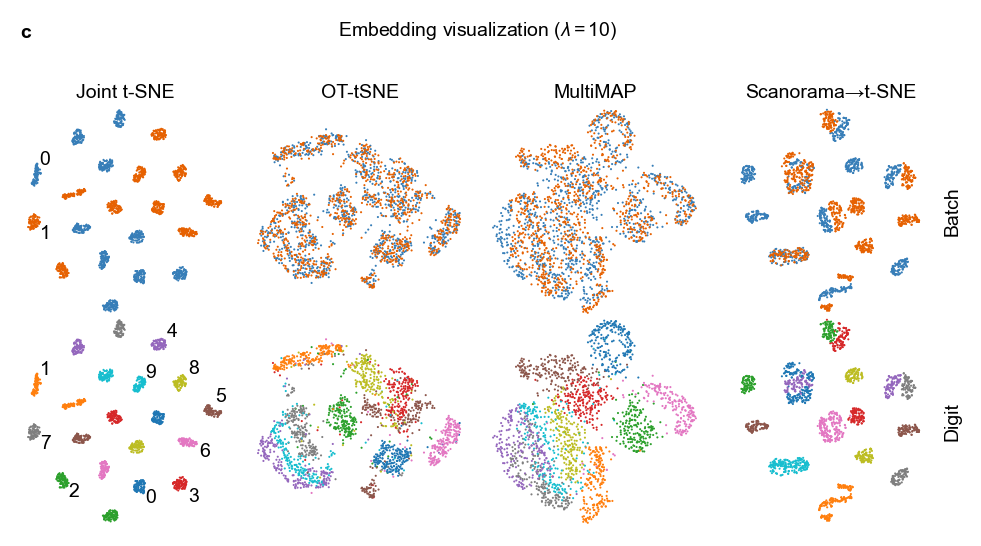

In [43]:
# The structured coordinate path is independent of embedding method parameters.
joint_path = (
    experiment.run_dir / "original/embeddings/joint_tsne/lambda_10/"
    "corruption_seed_0/embedding_seed_0.npz"
)
unintegrated = saved_synthetic.load_coordinates(joint_path, len(labels0) + len(labels1))
with plt.rc_context({"figure.constrained_layout.use": False}):
    fig = plt.figure(figsize=layout.full_width(3.0))
    fig.subplots_adjust(left=0.04, right=0.96, bottom=0.06, top=0.88)
    grid = fig.add_gridspec(1, 1)
    drawing.representative_embeddings(
        fig,
        grid[0],
        experiment.run_dir / "original",
        labels0,
        labels1,
        unintegrated=unintegrated,
        band=(0.08, 0.78),  # reserve a separate line for the gallery heading
        letter="C",
        centred=True,
    )
    drawing.lay_out_panels(fig)
    plt.show()

### Paper panels D and E: embedding purity and batch mixing
Average embedding seeds within corruption draws, then summarize across draws below.
The manuscript's downstream panel function uses these summaries directly, including SD bars.
With one corruption seed (smoke mode), between-draw SD is undefined and no SD bar is shown.

In [44]:
if RUN_EXPERIMENT:
    if "preprocessing" not in experiment.results:
        experiment.results["preprocessing"] = None
    experiment.per_corruption_summary = (
        experiment.results.groupby(
            [
                "mode",
                "magnitude",
                "method_id",
                "method",
                "display_method",
                "epsilon_policy",
                "rel_reg",
                "effective_k",
                "preprocessing",
                "corruption_seed",
            ],
            dropna=False,
        )
        .agg(
            purity=("purity", "mean"),
            purity_embedding_sd=("purity", "std"),
            kbet=("kbet", "mean"),
            kbet_embedding_sd=("kbet", "std"),
            n_embedding_seeds=("embedding_seed", "size"),
        )
        .reset_index()
    )
    experiment.summary = (
        experiment.per_corruption_summary.groupby(
            [
                "mode",
                "magnitude",
                "method_id",
                "method",
                "display_method",
                "epsilon_policy",
                "rel_reg",
                "effective_k",
                "preprocessing",
            ],
            dropna=False,
        )
        .agg(
            purity=("purity", "mean"),
            purity_std=("purity", "std"),
            purity_embedding_sd_mean=("purity_embedding_sd", "mean"),
            kbet=("kbet", "mean"),
            kbet_std=("kbet", "std"),
            kbet_embedding_sd_mean=("kbet_embedding_sd", "mean"),
            n_corruption_seeds=("corruption_seed", "size"),
        )
        .reset_index()
    )
    experiment.save_stage("summary")
else:
    print("Using saved artifacts for this stage.")

Using saved artifacts for this stage.


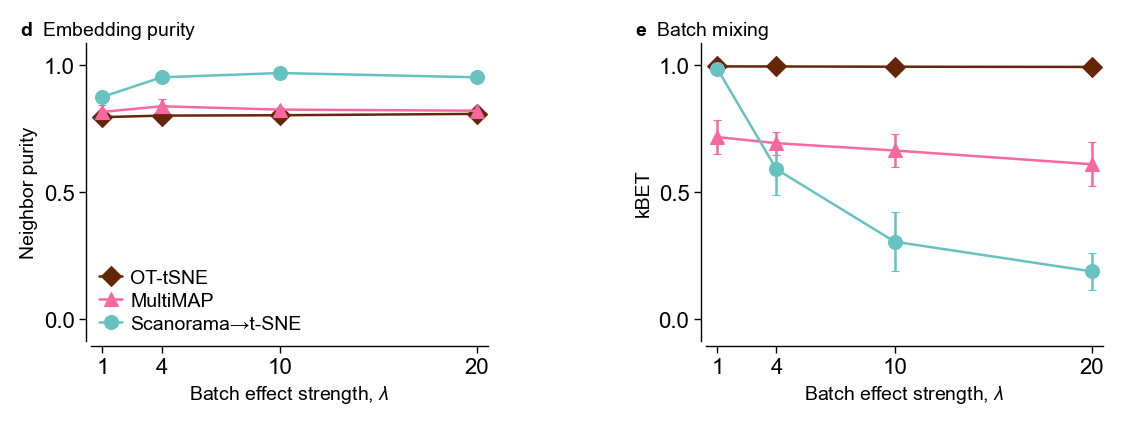

In [45]:
embedding_view = SimpleNamespace(summary=experiment.summary) if RUN_EXPERIMENT else runs
with plt.rc_context({"figure.constrained_layout.use": False}):
    fig = plt.figure(figsize=layout.full_width(2.1))
    grid = fig.add_gridspec(1, 2, wspace=0.55)
    drawing.downstream_panels(
        fig, (grid[0], grid[1]), embedding_view, letters=("D", "E"), purity_ylabel="Neighbor purity"
    )
    drawing.lay_out_panels(fig)
    plt.show()

## 9. Aggregate and inspect results
Average embedding seeds within each corruption seed first; only then compute means and sample SD
across corruption draws. A single draw has undefined SD, rather than a fabricated zero.
Stable `method_id` values identify configurations; display labels and parameter columns stay separate.
Raw evaluations, per-corruption summaries, and aggregate summaries are separate CSV artifacts.

In [46]:
# Load saved artifacts after either execution mode.
runs = experiment.load_saved()
summary = runs.summary
preview = summary.copy()
display(
    preview.loc[
        preview["mode"].eq("original"),
        [
            "magnitude",
            "display_method",
            "epsilon_policy",
            "rel_reg",
            "effective_k",
            "purity",
            "purity_std",
            "kbet",
            "kbet_std",
        ],
    ]
    .head(16)
    .round(3)
)
print("Saved run:", experiment.run_dir)

,magnitude,display_method,epsilon_policy,rel_reg,effective_k,purity,purity_std,kbet,kbet_std
0,1.0,MultiMAP · default,NaN,NaN,NaN,0.816,0.025,0.716,0.067
1,1.0,OT-tSNE · adaptive ε · rel_reg=10,adaptive_per_magnitude,10.0,15.0,0.803,0.002,0.993,0.001
2,1.0,OT-tSNE · adaptive ε · rel_reg=1,adaptive_per_magnitude,1.0,15.0,0.795,0.002,0.994,0.001
3,1.0,OT-tSNE · fixed ε · rel_reg=10,fixed_at_lambda_0,10.0,15.0,0.802,0.002,0.994,0.000
4,1.0,OT-tSNE · fixed ε · rel_reg=1,fixed_at_lambda_0,1.0,15.0,0.797,0.002,0.995,0.001
5,1.0,Scanorama → t-SNE,NaN,NaN,NaN,0.874,0.005,0.985,0.001
6,4.0,MultiMAP · default,NaN,NaN,NaN,0.838,0.028,0.692,0.045
7,4.0,OT-tSNE · adaptive ε · rel_reg=10,adaptive_per_magnitude,10.0,15.0,0.804,0.003,0.992,0.002
8,4.0,OT-tSNE · adaptive ε · rel_reg=1,adaptive_per_magnitude,1.0,15.0,0.801,0.002,0.994,0.001
9,4.0,OT-tSNE · fixed ε · rel_reg=10,fixed_at_lambda_0,10.0,15.0,0.801,0.002,0.994,0.000


Saved run: /Users/azharakhmetova/ne-aligned-submitted/results/mnist_orthogonal_batch_effect/mnist_orthogonal_batch_effect__seed0__8274e751


## 10. Reproduce the synthetic paper figure from saved results
The explicit run above is reloaded through `paper.inputs.synthetic.load_experiment()`.
`build_variant()` is the same callable used by `scripts/figures/synthetic.py`; no notebook-only
layout exists. It reconstructs the recorded MNIST/PCA for illustration and reads saved coordinates
and metrics. It never fits an integration method.

The current gallery requires λ=10, corruption/embedding seed 0, adaptive ε with rel_reg=1,
the configured MultiMAP profile, and Scanorama. Keep those entries when creating a figure-compatible run.
`SAVE_PAPER_FIGURE=False` previews in a temporary directory; enable the top-level switch to save
under the canonical `results/paper_figures/synthetic_experiment/final/` directory.

Browse `data/construction.npz`, representation-specific `diagnostics/*.csv`,
`metrics/embedding_metrics_{raw,per_corruption,summary}.csv`, and
`embeddings/<method-id>/lambda_*/corruption_seed_*/embedding_seed_*.{npz,json}`.
The manifest stores exact settings; each embedding has a readable metadata sidecar.

Figure input — Original MNIST: /Users/azharakhmetova/ne-aligned-submitted/results/mnist_orthogonal_batch_effect/mnist_orthogonal_batch_effect__seed0__8274e751/original
Figure input — Projected control: /Users/azharakhmetova/ne-aligned-submitted/results/mnist_orthogonal_batch_effect/mnist_orthogonal_batch_effect__seed0__8274e751/signal_projected


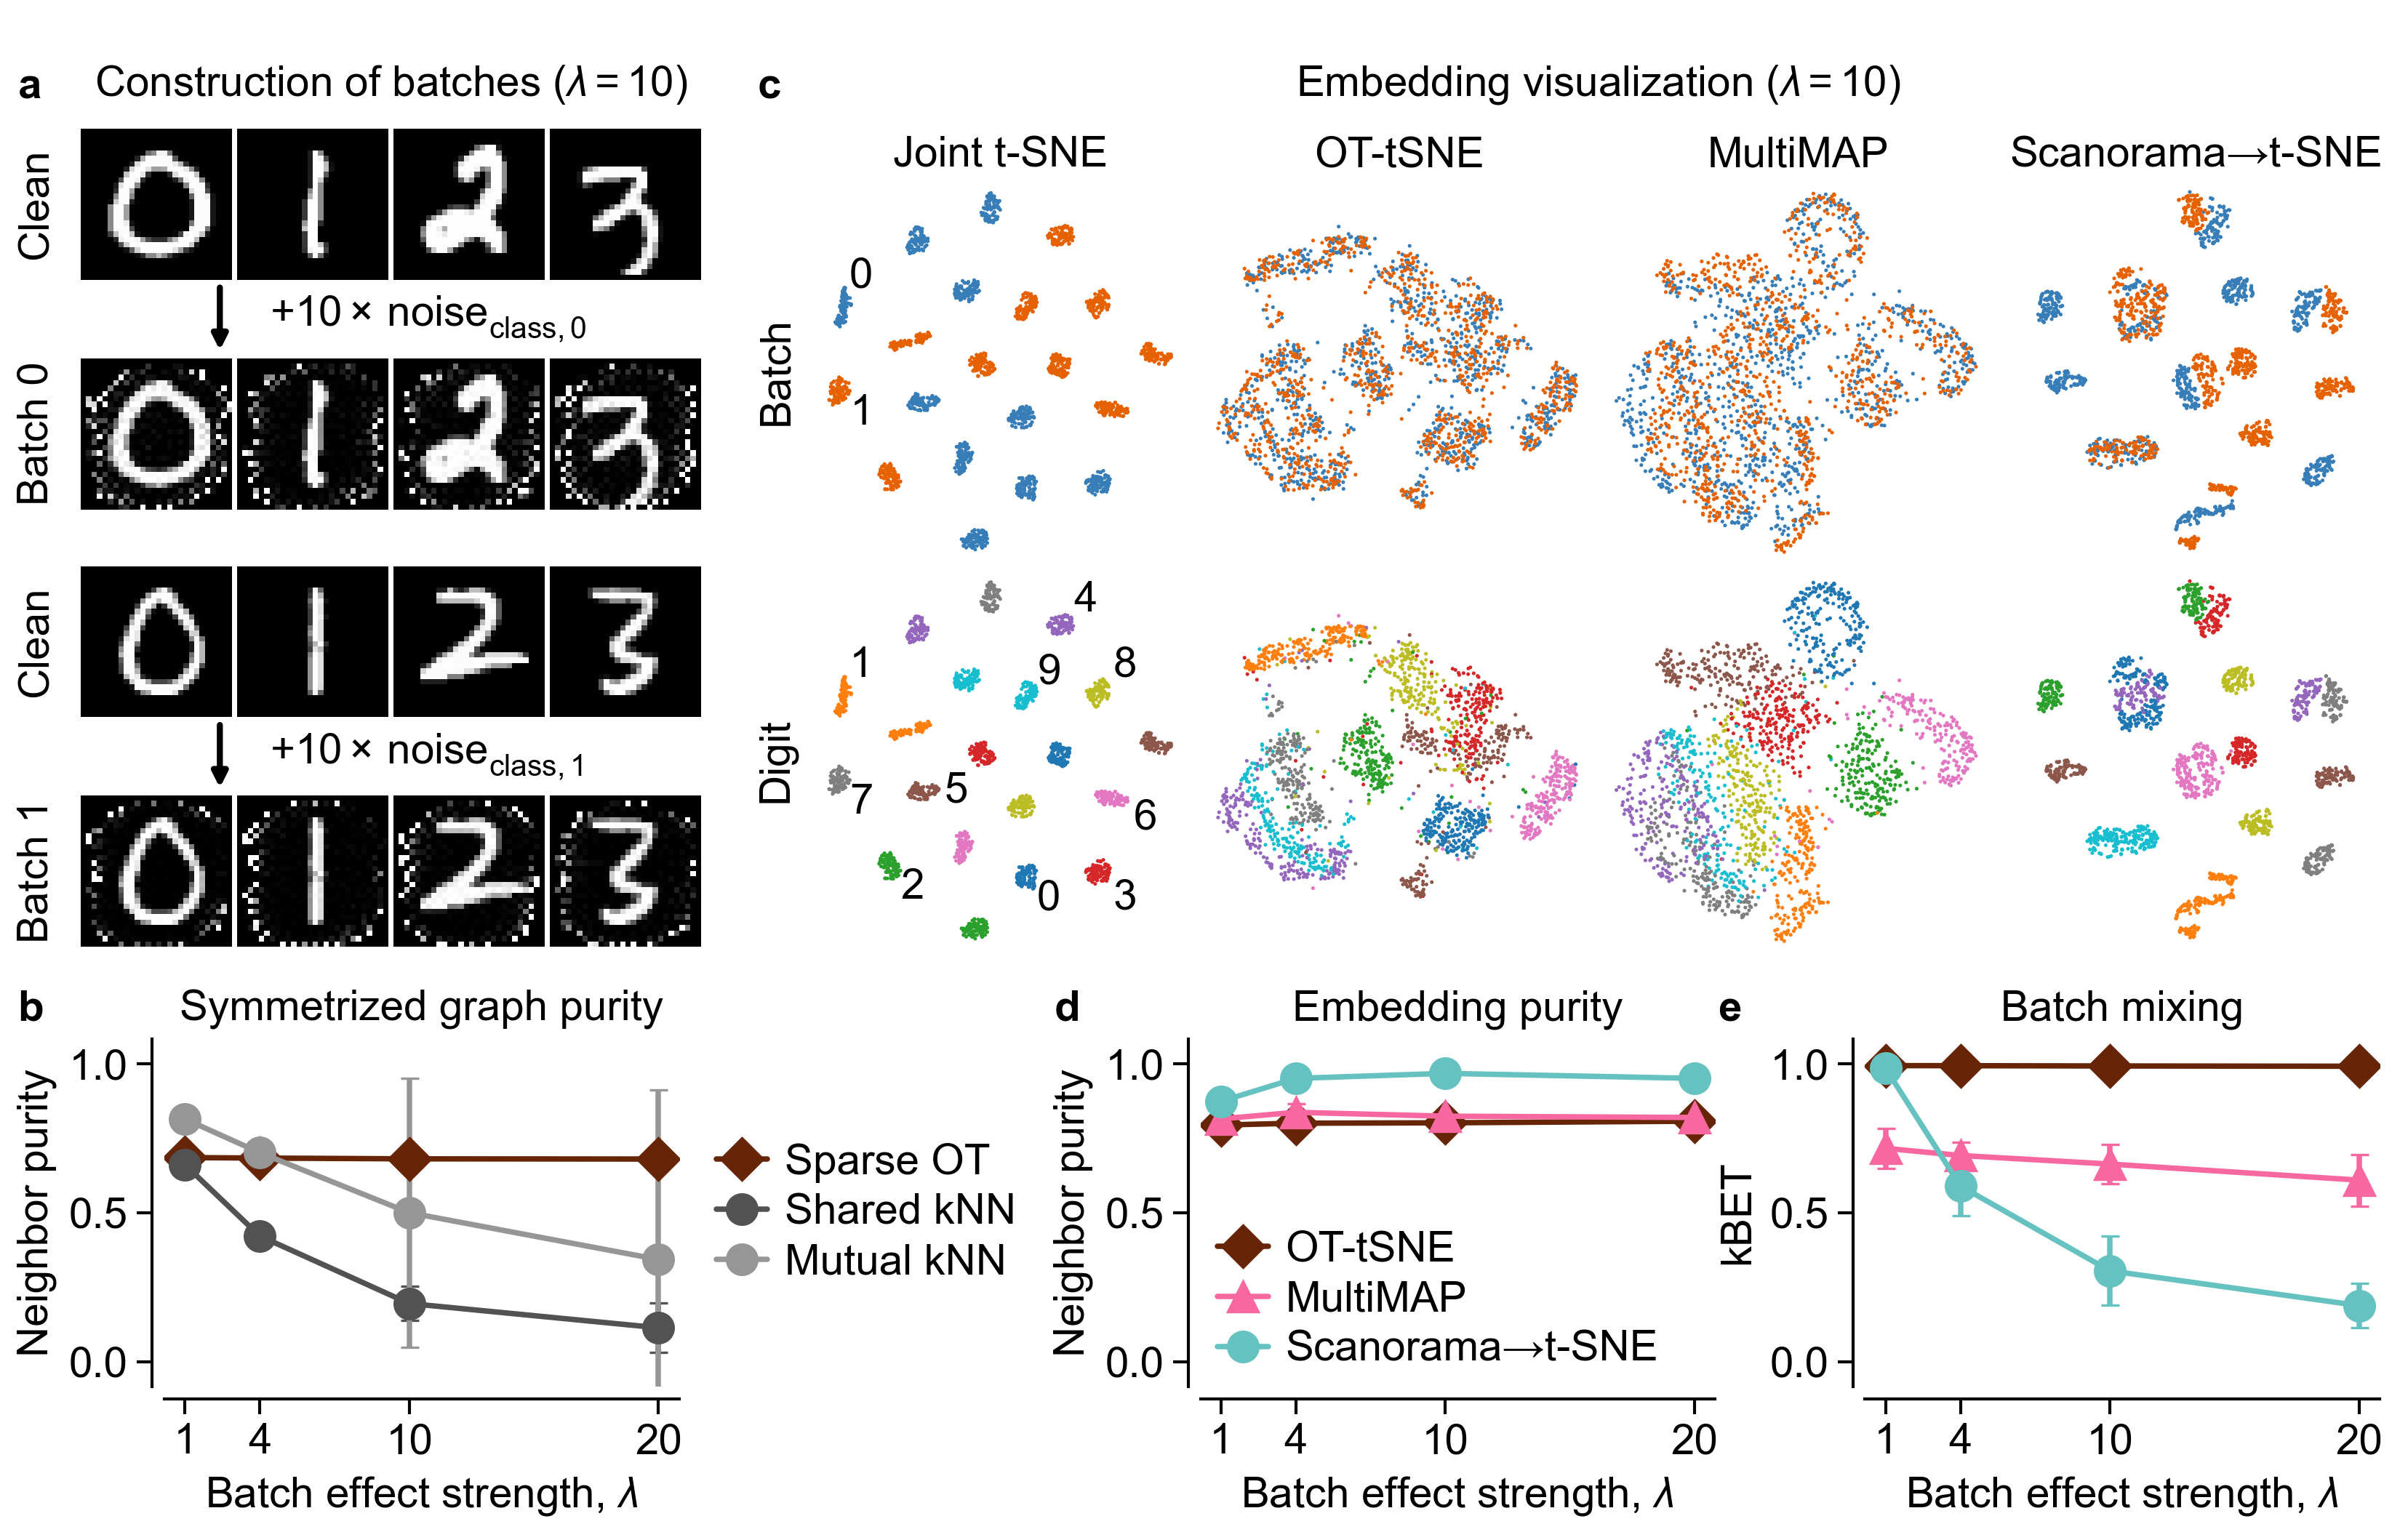

In [47]:
from tempfile import TemporaryDirectory
from ne_aligned_utils.paper import layout
from ne_aligned_utils.paper.figures.synthetic import PANEL_TITLE_PT

for mode, directory in runs.run_dirs.items():
    print(f"Figure input — {saved_synthetic.MODE_LABEL[mode]}: {directory}")


def reproduce_paper_figure(output_dir):
    with (
        layout.paper_style(),
        plt.rc_context(
            {
                key: PANEL_TITLE_PT
                for key in ("xtick.labelsize", "ytick.labelsize", "legend.fontsize")
            }
        ),
    ):
        return build_variant(
            runs.variant, source_root=SOURCE_ROOT, output_dir=output_dir, prepared=runs
        )


if SAVE_PAPER_FIGURE:
    figure_paths = reproduce_paper_figure(ROOT / "results/paper_figures/synthetic_experiment/final")
    display(Image(filename=str(figure_paths[-1])))
    print(f"Saved {len(figure_paths)} paper layouts.")
else:
    with TemporaryDirectory(prefix="mnist-paper-preview-") as preview:
        figure_paths = reproduce_paper_figure(Path(preview))
        display(Image(data=figure_paths[-1].read_bytes()))